# Приближённое решение задачи Коши

Рассматривается задача

$$u''+\frac{1}{2(1+x)}u'-\frac{1+2x}{2(1+x)}u=\frac{3\cos x-(3+4x)\sin x}{2\sqrt{1+x}},$$

$$u(0)=1,\qquad u'(0)=0,$$

с точным решением

$$u_0(x)=\sqrt{1+x}\sin x+e^{-x}.$$

Вычисления выполняются вручную по формулам методов: Эйлера второго порядка, Рунге–Кутты четвёртого порядка и Адамса–Башфорта третьего порядка.

## Сведение к системе первого порядка

Положим $v=u'$. Тогда $u'=v$, а из исходного уравнения

$$v'=\frac{3\cos x-(3+4x)\sin x}{2\sqrt{1+x}}-\frac{v}{2(1+x)}+\frac{1+2x}{2(1+x)}u.$$

Обозначим $Y=(u,v)^T$ и $Y'=F(x,Y)$. Начальное значение: $Y(0)=(1,0)^T$.

### Идея методов
- **Эйлер 2**: сначала прогнозируется конец шага наклоном в начале, затем берётся среднее наклонов в начале и в спрогнозированной конечной точке. Это метод второго порядка.
- **RK4**: на каждом шаге вычисляются четыре наклона в начале, двух промежуточных точках и конце; их взвешенное среднее даёт четвёртый порядок.
- **Адамс–Башфорт 3**: используется информация о трёх уже известных производных. Первые две точки нужны для запуска и получаются RK4.

Оценка Рунге для метода порядка $p$ имеет вид $R_i=\frac {|u_i(h)-u_i(2h)|} {2^p-1}$. Для Эйлера второго порядка $p=2$,
поэтому знаменатель равен $3$.

In [42]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

In [43]:
def F(x, Y):
    """Правая часть системы Y' = F(x, Y), Y=(u,v)."""
    u, v = Y
    forcing = (3.0 * np.cos(x) - (3.0 + 4.0 * x) * np.sin(x)) / (2.0 * np.sqrt(1.0 + x))
    return np.array(
        [v, forcing - v / (2.0 * (1.0 + x)) + (1.0 + 2.0 * x) * u / (2.0 * (1.0 + x))]
    )


def exact_u(x):
    return np.sqrt(1.0 + x) * np.sin(x) + np.exp(-x)


def grid(h, a=0.0, b=1.0):
    n = int(round((b - a) / h))
    return np.linspace(a, b, n + 1)

## Метод Эйлера второго порядка


$$k_1=F(x_i,Y_i),\quad Y^*=Y_i+hk_1,$$
$$k_2=F(x_i+h,Y^*),\quad Y_{i+1}=Y_i+\frac h2(k_1+k_2).$$

In [44]:
def euler2(h, a=0.0, b=1.0):
    x = grid(h, a, b)
    Y = np.zeros((len(x), 2))
    Y[0] = np.array([1.0, 0.0])

    for i in range(len(x) - 1):
        k1 = F(x[i], Y[i])
        Y_predict = Y[i] + h * k1
        k2 = F(x[i + 1], Y_predict)
        Y[i + 1] = Y[i] + 0.5 * h * (k1 + k2)
    return x, Y

## Метод Рунге–Кутты четвёртого порядка

$$k_1=F(x_i,Y_i),$$
$$k_2=F(x_i+h/2,Y_i+hk_1/2),$$
$$k_3=F(x_i+h/2,Y_i+hk_2/2),$$
$$k_4=F(x_i+h,Y_i+hk_3),$$
$$Y_{i+1}=Y_i+\frac h6(k_1+2k_2+2k_3+k_4).$$

In [45]:
def rk4_step(xi, Yi, h):
    k1 = F(xi, Yi)
    k2 = F(xi + h / 2.0, Yi + h * k1 / 2.0)
    k3 = F(xi + h / 2.0, Yi + h * k2 / 2.0)
    k4 = F(xi + h, Yi + h * k3)
    return Yi + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def rk4(h, a=0.0, b=1.0):
    x = grid(h, a, b)
    Y = np.zeros((len(x), 2))
    Y[0] = np.array([1.0, 0.0])
    for i in range(len(x) - 1):
        Y[i + 1] = rk4_step(x[i], Y[i], h)
    return x, Y

## Метод Адамса–Башфорта третьего порядка

$$Y_{i+1}=Y_i+\frac h{12}\left(23F_i-16F_{i-1}+5F_{i-2}\right).$$

Это многошаговая формула. Так как для первого шага нет $F_{-1}$ и $F_{-2}$, первые две точки вычисляются вручную RK4. После этого применяется формула Адамса.

In [ ]:
def adams3(h, a=0.0, b=1.0):
    x = grid(h, a, b)
    Y = np.zeros((len(x), 2))
    Y[0] = np.array([1.0, 0.0])

    if len(x) > 1:
        Y[1] = rk4_step(x[0], Y[0], h)
    if len(x) > 2:
        Y[2] = rk4_step(x[1], Y[1], h)

    for i in range(2, len(x) - 1):
        Fi = F(x[i], Y[i])
        Fim1 = F(x[i - 1], Y[i - 1])
        Fim2 = F(x[i - 2], Y[i - 2])
        Y[i + 1] = Y[i] + h * (23.0 * Fi - 16.0 * Fim1 + 5.0 * Fim2) / 12.0
    return x, Y

## Решение при $h=0.05$ и сравнение с точным решением

In [ ]:
h = 0.05
solutions = {
    "Euler 2": euler2(h),
    "RK4": rk4(h),
    "Adams 3": adams3(h),
}


## Визуализация решений и ошибок

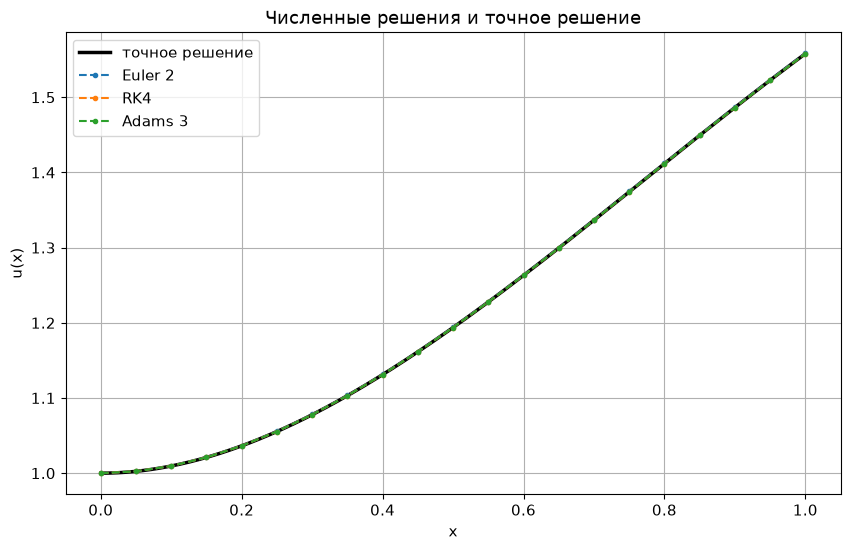

In [ ]:
x_plot = np.linspace(0.0, 1.0, 500)
plt.figure()
plt.plot(x_plot, exact_u(x_plot), "k-", lw=2.5, label="точное решение")
for name, (x, Y) in solutions.items():
    plt.plot(x, Y[:, 0], "o--", ms=3, label=name)
plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("Численные решения и точное решение")
plt.legend()
plt.show()


## Оценка точности по Рунге для Эйлера второго порядка

Сравниваем сетки $h=0.05$ и $2h=0.1$. Узлу $x_j$ грубой сетки соответствует узел $x_{2j}$ подробной сетки. Поскольку $p=2$,

$$R_j=\frac{|u_{2j}^{(0.05)}-u_j^{(0.1)}|}{3}.$$

In [64]:
x_fine, Y_fine = euler2(0.05)
x_coarse, Y_coarse = euler2(0.10)
Y_fine_on_coarse = Y_fine[::2]
runge_u = np.abs(Y_fine_on_coarse[:, 0] - Y_coarse[:, 0]) / 3.0
runge_v = np.abs(Y_fine_on_coarse[:, 1] - Y_coarse[:, 1]) / 3.0

# print(f"{'x':>8} {'u(h)':>16} {'u(2h)':>16} {'Runge u':>16} {'actual error':>16}")
# for j, xj in enumerate(x_coarse):
#     actual = abs(Y_fine_on_coarse[j, 0] - exact_u(xj))
#     print(
#         f"{xj:8.2f} {Y_fine_on_coarse[j, 0]:16.10f} "
#         f"{Y_coarse[j, 0]:16.10f} {runge_u[j]:16.6e} {actual:16.6e}"
#     )

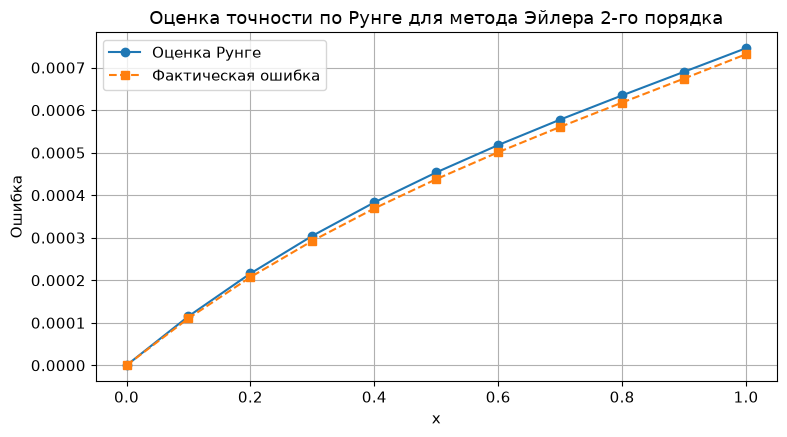

In [ ]:
plt.figure(figsize=(8, 4.5))

plt.plot(x_coarse, runge_u, "o-", label="Оценка Рунге")

actual_errors = np.abs(Y_fine_on_coarse[:, 0] - exact_u(x_coarse))

plt.plot(x_coarse, actual_errors, "s--", label="Фактическая ошибка")

plt.xlabel("x")
plt.ylabel("Ошибка")
plt.title("Оценка точности по Рунге для метода Эйлера 2-го порядка")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
j_max = np.argmax(runge_u)

print(f"Максимум R(x) = {runge_u[j_max]:.6e} достигается при x = {x_coarse[j_max]:.2f}")

Максимум R(x) = 7.456844e-04 достигается при x = 1.00


## График сходимости по сетке

Для каждого метода считаем $E(h)=\max_i|u_i-u_0(x_i)|$ на нескольких сетках. Если $E(h)\sim Ch^p$, то наклон прямой на графике `log(error)` от `log(h)` равен $p$.


Euler 2
--------------------------------------------------
Теоретический порядок: 2
Порядок по МНК (polyfit): 2.004364

RK4
--------------------------------------------------
Теоретический порядок: 4
Порядок по МНК (polyfit): 4.009715

Adams 3
--------------------------------------------------
Теоретический порядок: 3
Порядок по МНК (polyfit): 2.971576


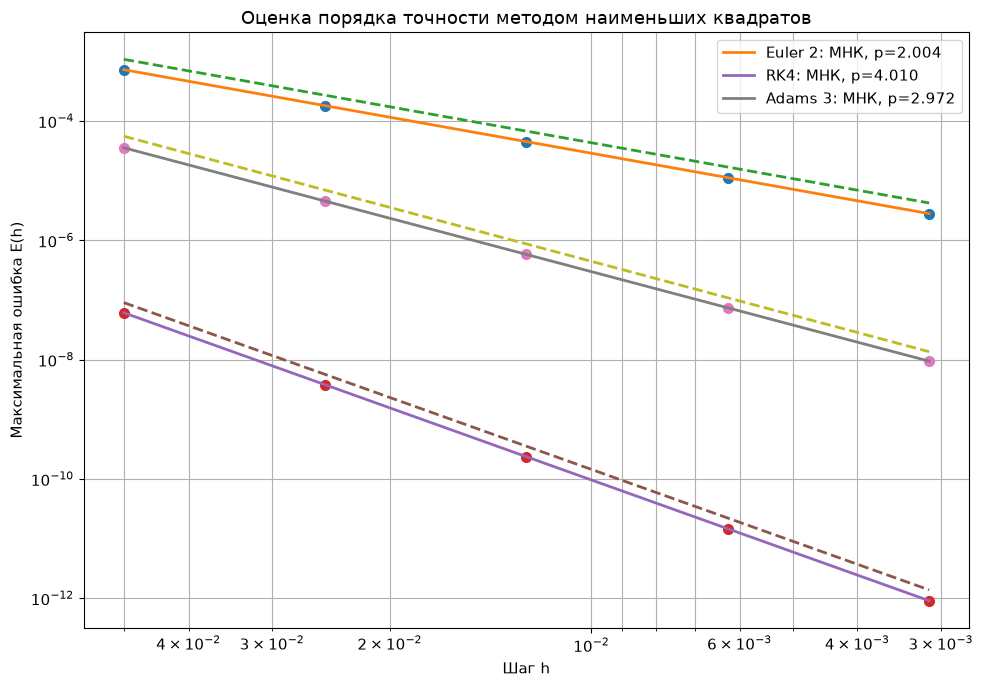

In [ ]:
def max_error(method, h):
    x, Y = method(h)
    error = np.abs(Y[:, 0] - exact_u(x))
    return np.max(error)


def convergence_data(method, hs):
    errors = np.array([max_error(method, h) for h in hs])

    log_h = np.log(hs)
    log_errors = np.log(errors)

    # polyfit возвращает [наклон, свободный член] = [p, a]
    p_num, a_num = np.polyfit(log_h, log_errors, 1)

    fitted_errors = np.exp(a_num + p_num * log_h)

    return errors, p_num, a_num, fitted_errors, log_h, log_errors


def theoretical_line(log_h, log_errors, p_theory):
    a_theory = np.mean(log_errors - p_theory * log_h)
    return a_theory, np.exp(a_theory + p_theory * log_h)


hs = np.array([0.05, 0.025, 0.0125, 0.00625, 0.003125])

methods = {
    "Euler 2": (euler2, 2),
    "RK4": (rk4, 4),
    "Adams 3": (adams3, 3),
}

plt.figure(figsize=(10, 7))

for name, (method, theoretical_order) in methods.items():
    errors, p_num, a_num, fitted_errors, log_h, log_errors = convergence_data(
        method, hs
    )

    a_theory, fitted_errors_theory = theoretical_line(
        log_h, log_errors, theoretical_order
    )

    print(f"\n{name}")
    print("-" * 50)
    print(f"Теоретический порядок: {theoretical_order}")
    print(f"Порядок по МНК (polyfit): {p_num:.6f}")

    # Данные
    plt.loglog(
        hs,
        errors,
        "o",
        markersize=7,
    )

    # Прямая по МНК (свободный наклон)
    plt.loglog(
        hs,
        fitted_errors,
        "-",
        linewidth=2,
        label=f"{name}: МНК, p={p_num:.3f}",
    )

    # Прямая с теоретическим наклоном
    plt.loglog(
        hs,
        1.5 * fitted_errors_theory,
        "--",
        linewidth=2,
    )

plt.xlabel("Шаг h")
plt.ylabel("Максимальная ошибка E(h)")
plt.title("Оценка порядка точности методом наименьших квадратов")
plt.grid(True, which="both")
plt.gca().invert_xaxis()
plt.legend()
plt.tight_layout()
plt.show()